# 09 · F2LLM embeddings on the tagging-method framework

This notebook asks whether the embeddings of a pretrained encoder, frozen, add anything to the
TF-IDF baseline on the eight focus tags. The encoder is
[F2LLM-0.6B](https://huggingface.co/codefuse-ai/F2LLM-0.6B) (v1, pinned to one revision of its
weights). It embeds every problem twice, the statement with its notes and the solution, each
cut at 1,024 tokens and prefixed with a fixed task instruction. The 9,964 embeddings are
computed once and cached, and three tagging methods are built on them. Each is a registered
method of the framework, frozen once (dev out of fold, test once) in `assets/methods/`:

| Method | What it is |
|---|---|
| `f2llm_probe` | A linear head (logistic regression, linear SVM or ridge) on the frozen embeddings of the statement and, when it helps, the solution |
| `f2llm_late_fusion` | The probe's scores and the frozen TF-IDF model's, each standardised per tag with held-out statistics, then blended with one tuned weight |
| `f2llm_early_fusion` | One linear SVM on the frozen TF-IDF feature blocks and the embedding blocks, side by side |

**Protocol.** The tuned configurations were chosen on the cross-fitted out-of-fold macro F1 of
the dev set alone ([ADR 0001](../docs/adr/0001-model-selection-protocol.md)): fold k's per-tag
thresholds come from the other four folds' out-of-fold scores. Each method scored the test set
once, when it was frozen. The CLI's method is chosen later and mechanically, on dev out-of-fold
macro F1 among the frozen methods whose slowest problem in `latency.csv` takes under 10 seconds
([ADR 0004](../docs/adr/0004-tagging-method-framework.md)); every test score below is a
reference, and nothing is chosen from it.

**Contents**
1. The question, the three methods, the protocol
2. The inputs: token lengths and the share cut at 1,024 tokens
3. Out-of-fold results
4. Per tag and per release era, paired with TF-IDF
5. Near-duplicate sensitivity
6. Thresholds: cross-fitted against pooled, and across the five folds
7. Tuning: the grids and their plateau
8. Late fusion's effective weights
9. Latency and eligibility
10. The test references
11. Caveats and takeaways

**Running it.** The notebook reads frozen files only: `assets/methods/f2llm_*/`,
`assets/methods/tfidf/` (checked against `assets/tfidf_baseline/`),
`assets/methods/label_prior/`, `assets/f2llm/` and
`assets/slices/self_identifying_solutions.csv`, besides the dataset for the labels. It loads no
model and fits nothing, so it needs neither a GPU nor `torch`, and runs in under a minute:

```bash
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/09_f2llm.ipynb
```

The lines under "What it shows" are computed from the frozen files by the cell above them, so
they follow the files when the notebook is executed again.

## 1. The question, the three methods, the protocol

Setup first. The dev set (3,988 problems, five folds) and the test set (994 problems) come from
the frozen split; the labels are the eight focus tags. The next cells read each method's frozen
predictions and scores, and those of the frozen method `tfidf`, the TF-IDF baseline of
[notebook 04](04_tfidf_baseline.ipynb), frozen by `tuning freeze`, which every method below is
compared with. The TF-IDF reference rows that the F2LLM package's `reference` command wrote in
`assets/f2llm/` are checked to be its rows, bit for bit.

A fourth method, `f2llm_setfit` (SetFit-style contrastive fine-tuning of the encoder with LoRA,
then the probe's head), is registered in the code but was not frozen in this run: its freeze
takes 5 to 7 hours of GPU, skipped by choice, so it has no score here.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from codeforces_tags.analysis.comparison import method_scores, slice_differences
from codeforces_tags.analysis.plotting import (
    plot_intervals,
    plot_latency,
    plot_method_f1,
    setup_style,
)
from codeforces_tags.config import (
    FOCUS_COLOR,
    FOCUS_TAGS,
    LATENCY_BUDGET_S,
    RELEASE_ERA_FIRST_YEAR,
    SELF_IDENTIFYING_FILE,
    TFIDF_TEST_MACRO_F1,
    TUNING_EXPORT_TOLERANCE,
)
from codeforces_tags.conformance import check_frozen_method
from codeforces_tags.data.labels import focus_labels
from codeforces_tags.data.loading import load_dataset
from codeforces_tags.evaluation.contamination import load_slice
from codeforces_tags.evaluation.predictions import load_predictions, load_run_record, load_scores
from codeforces_tags.evaluation.report import ALL_PROBLEMS, EARLY_ERA, LATE_ERA, compare, evaluate
from codeforces_tags.evaluation.timing import latency_summary, load_latency
from codeforces_tags.methods import METHODS, method_dir
from codeforces_tags.methods.f2llm.settings import (
    EARLY_FUSION,
    LATE_FUSION,
    MAX_LENGTH,
    PROBE,
    SHARED_ASSETS_DIR,
)
from codeforces_tags.model.thresholds import (
    apply_thresholds,
    cross_fitted_predictions,
    per_tag_thresholds,
)
from codeforces_tags.splitting import load_split, release_years, select_part
from codeforces_tags.tuning.results import load_tuning_results

setup_style()
pd.set_option("display.max_colwidth", 110)

# The year the share of `math` rose (notebook 01, section 5), for the `math` split of section 4.
MATH_SHIFT_YEAR = 2019

df = load_dataset()
split = load_split()
dev = select_part(df, split, "dev")
test = select_part(df, split, "test")
labels, test_labels = focus_labels(dev), focus_labels(test)
folds, groups, test_groups = dev["fold"], dev["group"], test["group"]
years = release_years(dev)
print(
    f"dev: {len(dev):,} problems in {folds.nunique()} folds and {groups.nunique():,} "
    f"near-duplicate groups; test: {len(test):,} problems"
)

dev: 3,988 problems in 5 folds and 3,919 near-duplicate groups; test: 994 problems


In [2]:
METHOD_NAMES = {
    "probe": PROBE,
    "late fusion": LATE_FUSION,
    "early fusion": EARLY_FUSION,
}
F2LLM = list(METHOD_NAMES)
TFIDF = "tfidf"  # the TF-IDF baseline: notebook 04's tag model, frozen by `tuning freeze`
for name in (*METHOD_NAMES.values(), TFIDF, "label_prior"):
    check_frozen_method(name, split=split)  # complete, and consistent with the frozen split
folders = {label: method_dir(name) for label, name in METHOD_NAMES.items()}
records = {label: load_run_record(folder) for label, folder in folders.items()}
tfidf_predictions = load_predictions(method_dir(TFIDF))
tfidf_scores = load_scores(method_dir(TFIDF))

# The TF-IDF reference rows of assets/f2llm/, written by the F2LLM package's `reference` command,
# are the frozen method's rows, bit for bit.
reference = pd.read_csv(
    SHARED_ASSETS_DIR / "tfidf_reference.csv",
    index_col=["part", "sample_id", "kind"],
    dtype={"part": "str", "kind": "str"},
    float_precision="round_trip",
)[list(FOCUS_TAGS)]
assert len(reference) == len(tfidf_predictions) + len(tfidf_scores)
reference_predictions = reference.xs("prediction", level="kind").astype("int64")
assert reference_predictions.reindex(tfidf_predictions.index).equals(tfidf_predictions)
assert reference.xs("score", level="kind").reindex(tfidf_scores.index).equals(tfidf_scores)

predictions_by_part = {
    part: {
        "label prior": load_predictions(method_dir("label_prior")).loc[part],
        "tf-idf": tfidf_predictions.loc[part],
        **{label: load_predictions(folder).loc[part] for label, folder in folders.items()},
    }
    for part in ("dev", "test")
}
scores_by_part = {
    part: {
        "tf-idf": tfidf_scores.loc[part],
        **{label: load_scores(folder).loc[part] for label, folder in folders.items()},
    }
    for part in ("dev", "test")
}
rows = {"dev": labels.index, "test": test_labels.index}
dev_predictions, test_predictions = (
    {label: frame.reindex(rows[part]) for label, frame in predictions_by_part[part].items()}
    for part in ("dev", "test")
)
dev_scores, test_scores = (
    {label: frame.reindex(rows[part]) for label, frame in scores_by_part[part].items()}
    for part in ("dev", "test")
)
# Every frame, predictions and scores apart (they share the method names): the tag columns, and
# a row for every problem of the part.
for part, kind, by_method in (
    ("dev", "predictions", dev_predictions),
    ("dev", "scores", dev_scores),
    ("test", "predictions", test_predictions),
    ("test", "scores", test_scores),
):
    for label, frame in by_method.items():
        assert list(frame.columns) == list(FOCUS_TAGS), (part, kind, label)
        assert not frame.isna().any().any(), (part, kind, label)

# The frozen method `tfidf` must give notebook 04's results, to the digit.
frozen_dev_f1 = load_tuning_results().out_of_fold.at["macro_f1", "f1"]
tfidf_dev_f1 = evaluate(labels, dev_predictions["tf-idf"]).macro_f1
tfidf_test_f1 = evaluate(test_labels, test_predictions["tf-idf"]).macro_f1
assert abs(tfidf_dev_f1 - frozen_dev_f1) <= TUNING_EXPORT_TOLERANCE
assert abs(tfidf_test_f1 - TFIDF_TEST_MACRO_F1) <= TUNING_EXPORT_TOLERANCE
print(
    f"tf-idf (the frozen method `{TFIDF}`): out-of-fold macro F1 {tfidf_dev_f1:.4f} (notebook "
    f"04: {frozen_dev_f1:.4f}); test {tfidf_test_f1:.4f}. The {len(reference):,} rows of "
    "tfidf_reference.csv are its rows, bit for bit."
)

tf-idf (the frozen method `tfidf`): out-of-fold macro F1 0.6629 (notebook 04: 0.6629); test 0.6888. The 9,964 rows of tfidf_reference.csv are its rows, bit for bit.


**What was frozen.** Each method's run record pins the commit, the recipe and the device its
files were computed on. The methods are not bit-reproducible across devices: `embed --device
cuda` computed the embeddings of the dev and test sets on the GPU, in batches, and `freeze` read
them from the cache, while a loaded method encodes each problem alone, on the GPU when torch
sees one, else on the CPU (`CODEFORCES_DEVICE`, `cpu` or `cuda`, overrides it). So
`freeze` checks a loaded method's live scores against the refit's on a few dev problems, and
`verify` against the frozen test scores, both at `score_atol` (the registry's value, below)
instead of exactly.
`supersedes` lists the sibling methods whose predictions were already committed when a method
was frozen: the three were frozen together, as parallel candidates fixed in advance.

In [3]:
pd.DataFrame(
    {
        label: {
            "recipe sha256": records[label].recipe_sha256[:12],
            "frozen at commit": str(records[label].git["commit"])[:10],
            "device": records[label].method_entries["device"],
            "dtype": records[label].method_entries["dtype"],
            "batch tokens": records[label].method_entries["batch_tokens"],
            "threads": records[label].method_entries["threads"],
            "supersedes": ", ".join(records[label].method_entries["supersedes"]) or "none",
            "dev in sample": records[label].method_entries["dev_in_sample"],
            "score_atol": METHODS[METHOD_NAMES[label]].score_atol,
        }
        for label in F2LLM
    }
)

,probe,late fusion,early fusion
recipe sha256,d888f63751d7,241a56a8f2f6,786d6d6b7a90
frozen at commit,f9006947d6,f9006947d6,f9006947d6
device,cuda,cuda,cuda
dtype,float32,float32,float32
batch tokens,32768,32768,32768
threads,6,6,6
supersedes,none,none,none
dev in sample,False,False,False
score_atol,0.00009,0.00009,0.00009


## 2. The inputs: token lengths and the share cut at 1,024 tokens

Each problem gives the encoder two inputs: the statement with its notes (the text the TF-IDF
statement block reads) and the solution's source code. An input is tokenised with its task
instruction in front and cut at 1,024 tokens, F2LLM v1's training length, keeping the end token;
a cut drops the end of the text, so the notes, which follow the statement, are cut first and
a long solution loses its last lines. `input_lengths.csv` holds the untruncated token count of
every problem's two encoder inputs, instruction and end token included.

,median,90th percentile,99th percentile,maximum,"share cut at 1,024","share cut, dev","share cut, test"
statement_tokens,537.0,832.0,1185.14,1743,0.031,0.032,0.024
solution_tokens,276.0,846.9,2846.71,24482,0.067,0.069,0.059


4,631,943 tokens in all, once cut at 1,024 (before the cut: 5,001,598)


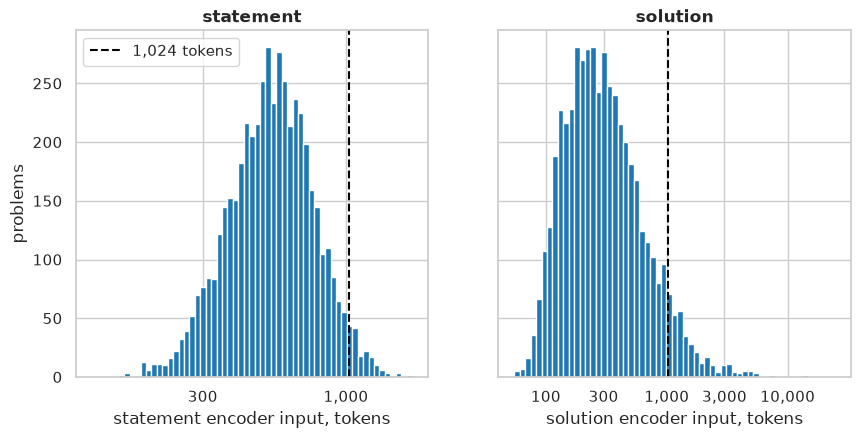

In [4]:
LENGTH_TICKS = (100, 300, 1_000, 3_000, 10_000)
lengths = pd.read_csv(SHARED_ASSETS_DIR / "input_lengths.csv", index_col="sample_id")
inputs = {"statement": "statement_tokens", "solution": "solution_tokens"}
cut = lengths > MAX_LENGTH
display(
    pd.DataFrame(
        {
            "median": lengths.median(),
            "90th percentile": lengths.quantile(0.9),
            "99th percentile": lengths.quantile(0.99),
            "maximum": lengths.max(),
            f"share cut at {MAX_LENGTH:,}": cut.mean(),
            "share cut, dev": cut.loc[dev.index].mean(),
            "share cut, test": cut.loc[test.index].mean(),
        }
    ).round(3)
)
print(
    f"{np.minimum(lengths, MAX_LENGTH).to_numpy().sum():,} tokens in all, once cut at "
    f"{MAX_LENGTH:,} (before the cut: {lengths.to_numpy().sum():,})"
)
figure, axes = plt.subplots(1, 2, sharey=True)
for ax, (name, column) in zip(axes, inputs.items(), strict=True):
    low, high = lengths[column].min(), lengths[column].max()
    ax.hist(lengths[column], bins=np.geomspace(low, high, 60), color=FOCUS_COLOR)
    ax.axvline(MAX_LENGTH, color="black", linestyle="--", label=f"{MAX_LENGTH:,} tokens")
    ax.set(xscale="log", xlabel=f"{name} encoder input, tokens", title=name)
    # Plain tick labels within the data, none on the minor ticks: a log axis spanning about one
    # decade labels its minor ticks too, and they overlap.
    ticks = [tick for tick in LENGTH_TICKS if low <= tick <= high]
    ax.set_xticks(ticks, labels=[f"{tick:,}" for tick in ticks])
    ax.tick_params(axis="x", which="minor", labelbottom=False)
axes[0].set_ylabel("problems")
axes[0].legend()
plt.show()

In [5]:
shares = cut.mean()
display(
    Markdown(
        "**What it shows**\n"
        + "\n".join(
            f"- **{name}**: median {lengths[column].median():.0f} tokens; "
            f"{shares[column]:.1%} of the problems are cut at {MAX_LENGTH:,} tokens."
            for name, column in inputs.items()
        )
    )
)

**What it shows**
- **statement**: median 537 tokens; 3.1% of the problems are cut at 1,024 tokens.
- **solution**: median 276 tokens; 6.7% of the problems are cut at 1,024 tokens.

## 3. Out-of-fold results

Every method's dev predictions are out of fold: a problem is predicted by a model fitted on the
four folds that do not hold it, with the thresholds chosen on the other folds' scores
([ADR 0001](../docs/adr/0001-model-selection-protocol.md)). `method_scores` scores them all on
the same group-bootstrap resamples (near-duplicate groups are drawn whole), so the intervals
and the paired differences with the frozen TF-IDF method (`tf-idf` in the tables) are
comparable. The label prior, the F1 floor, shows what predicting from the tag frequencies alone
scores.

In [6]:
oof = method_scores(labels, dev_predictions, groups, baseline="tf-idf")
overall = pd.concat(
    {metric: oof.xs(metric, level="metric") for metric in ("macro_f1", "micro_f1")}, axis=1
)
overall.round(3)

macro_f1                                            micro_f1  \
                   f1 f1_low f1_high  delta delta_low delta_high       f1   
method                                                                      
label prior     0.149  0.144   0.153 -0.514    -0.534     -0.494    0.158   
tf-idf          0.663  0.642   0.683  0.000     0.000      0.000    0.617   
probe           0.709  0.689   0.726  0.046     0.031      0.060    0.664   
late fusion     0.706  0.687   0.723  0.043     0.028      0.057    0.663   
early fusion    0.702  0.682   0.719  0.039     0.026      0.053    0.657   

                                                         
             f1_low f1_high  delta delta_low delta_high  
method                                                   
label prior   0.153   0.163 -0.460    -0.473     -0.447  
tf-idf        0.604   0.632  0.000     0.000      0.000  
probe         0.650   0.677  0.046     0.033      0.059  
late fusion   0.648   0.676  0.045     0.033      0.057  
early fusion  0.642   0.671  0.040     0.028      0.051

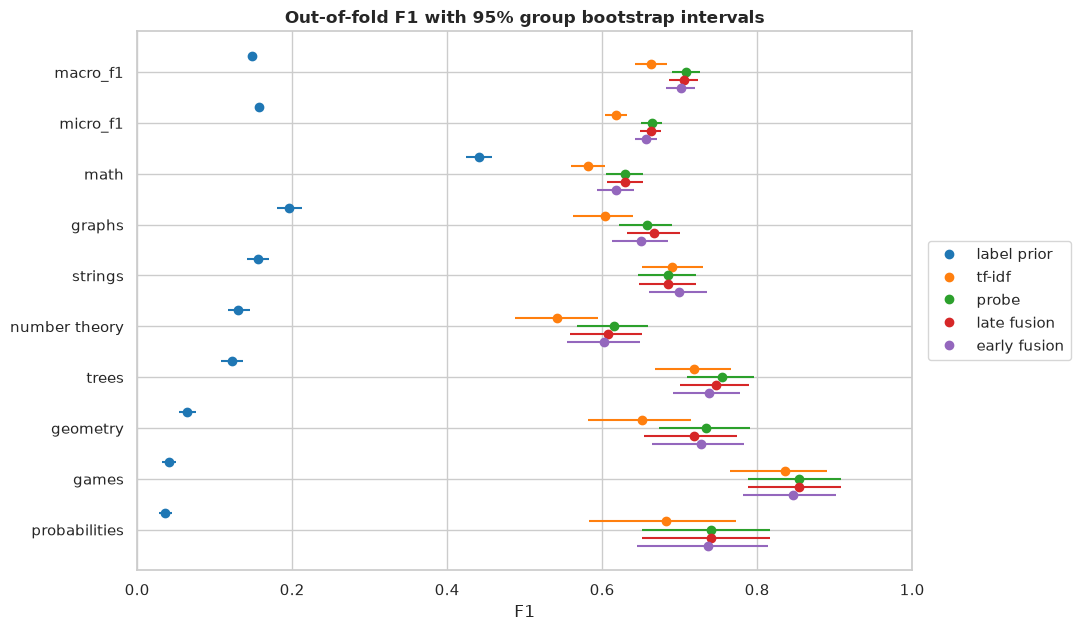

In [7]:
ax = plot_method_f1(oof)
ax.figure.set_size_inches(10, 7)
ax.set(title="Out-of-fold F1 with 95% group bootstrap intervals")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()

**Per tag.** The F1 of each focus tag, over all dev problems:

In [8]:
oof["f1"].unstack("metric")[["macro_f1", "micro_f1", *FOCUS_TAGS]].round(3)

metric,macro_f1,micro_f1,math,graphs,strings,number theory,trees,geometry,games,probabilities
method,,,,,,,,,,
label prior,0.149,0.158,0.441,0.196,0.156,0.130,0.123,0.065,0.041,0.036
tf-idf,0.663,0.617,0.582,0.603,0.690,0.541,0.719,0.652,0.835,0.682
probe,0.709,0.664,0.629,0.657,0.685,0.615,0.755,0.735,0.854,0.741
late fusion,0.706,0.663,0.629,0.667,0.685,0.607,0.746,0.718,0.854,0.741
early fusion,0.702,0.657,0.618,0.650,0.699,0.602,0.737,0.728,0.847,0.737


**Without the self-identifying solutions.** A solution that names its own problem (a
Codeforces URL, a contest id, or copied statement text) makes the tags easier to recall for an
encoder that has seen Codeforces pages. The rule is frozen in `config.py`
(`SELF_IDENTIFYING_FILE`); the same scores, with those dev problems left out:

In [9]:
slice_ = load_slice(SELF_IDENTIFYING_FILE)
clean = ~labels.index.isin(slice_.index)
print(
    f"{(~clean).sum()} of the {len(slice_)} self-identifying problems are in dev "
    f"({(slice_['part'] == 'test').sum()} are in test); {clean.sum():,} dev problems remain"
)
oof_clean = method_scores(
    labels[clean],
    {label: frame[clean] for label, frame in dev_predictions.items()},
    groups[clean],
    baseline="tf-idf",
)
macro = oof.xs("macro_f1", level="metric")
macro_clean = oof_clean.xs("macro_f1", level="metric")
pd.concat({"all dev problems": macro, "without the self-identifying": macro_clean}, axis=1).round(3)

50 of the 66 self-identifying problems are in dev (16 are in test); 3,938 dev problems remain


all dev problems                                             \
                           f1 f1_low f1_high  delta delta_low delta_high   
method                                                                     
label prior             0.149  0.144   0.153 -0.514    -0.534     -0.494   
tf-idf                  0.663  0.642   0.683  0.000     0.000      0.000   
probe                   0.709  0.689   0.726  0.046     0.031      0.060   
late fusion             0.706  0.687   0.723  0.043     0.028      0.057   
early fusion            0.702  0.682   0.719  0.039     0.026      0.053   

             without the self-identifying                                  \
                                       f1 f1_low f1_high  delta delta_low   
method                                                                      
label prior                         0.148  0.144   0.153 -0.515    -0.534   
tf-idf                              0.663  0.642   0.683  0.000     0.000   
probe                               0.708  0.689   0.728  0.045     0.031   
late fusion                         0.706  0.686   0.725  0.043     0.029   
early fusion                        0.702  0.682   0.721  0.039     0.026   

                         
             delta_high  
method                   
label prior      -0.494  
tf-idf            0.000  
probe             0.060  
late fusion       0.057  
early fusion      0.053

In [10]:
ranking = macro["f1"].sort_values(ascending=False)
lines = [
    "**What it shows**",
    "- **Ranking by out-of-fold macro F1**: "
    + ", ".join(f"{label} {score:.3f}" for label, score in ranking.items())
    + ".",
]
for label, row in macro.loc[F2LLM].iterrows():
    clean_row = macro_clean.loc[label]
    verdict = (
        "the interval excludes 0, ahead"
        if row["delta_low"] > 0
        else "the interval excludes 0, behind"
        if row["delta_high"] < 0
        else "the interval includes 0, level within the noise"
    )
    lines.append(
        f"- **{label}** against tf-idf: {row['delta']:+.3f} [{row['delta_low']:+.3f}, "
        f"{row['delta_high']:+.3f}], {verdict}; without the self-identifying problems "
        f"{clean_row['delta']:+.3f} [{clean_row['delta_low']:+.3f}, "
        f"{clean_row['delta_high']:+.3f}]."
    )
display(Markdown("\n".join(lines)))

**What it shows**
- **Ranking by out-of-fold macro F1**: probe 0.709, late fusion 0.706, early fusion 0.702, tf-idf 0.663, label prior 0.149.
- **probe** against tf-idf: +0.046 [+0.031, +0.060], the interval excludes 0, ahead; without the self-identifying problems +0.045 [+0.031, +0.060].
- **late fusion** against tf-idf: +0.043 [+0.028, +0.057], the interval excludes 0, ahead; without the self-identifying problems +0.043 [+0.029, +0.057].
- **early fusion** against tf-idf: +0.039 [+0.026, +0.053], the interval excludes 0, ahead; without the self-identifying problems +0.039 [+0.026, +0.053].

**The three F2LLM methods against each other.** Late fusion and early fusion add the TF-IDF
model back to the embeddings, in two ways. The paired difference of the out-of-fold macro F1
for each pair of the three, on the same resamples:

In [11]:
F2LLM_PAIRS = (("probe", "late fusion"), ("probe", "early fusion"), ("late fusion", "early fusion"))
between = pd.DataFrame(
    {
        f"{candidate} minus {baseline}": compare(
            labels, dev_predictions[baseline], dev_predictions[candidate], groups
        ).loc["macro_f1"]
        for baseline, candidate in F2LLM_PAIRS
    }
).T
tied = (between["delta_low"] <= 0) & (between["delta_high"] >= 0)  # the interval includes 0
between.round(4)

,baseline,candidate,delta,delta_low,delta_high
late fusion minus probe,0.7087,0.7057,-0.0030,-0.0079,0.0016
early fusion minus probe,0.7087,0.7022,-0.0065,-0.0168,0.0034
early fusion minus late fusion,0.7057,0.7022,-0.0035,-0.0135,0.0060


In [12]:
lines = ["**What it shows**"]
lines += [
    f"- **{pair}**: {row['delta']:+.4f} [{row['delta_low']:+.4f}, {row['delta_high']:+.4f}], "
    f"the interval {'includes' if tied[pair] else 'excludes'} 0."
    for pair, row in between.iterrows()
]
lines.append(
    "- Every interval includes 0: on dev, the three cannot be told apart."
    if tied.all()
    else f"- The intervals that exclude 0: {', '.join(between.index[~tied])}."
)
display(Markdown("\n".join(lines)))

**What it shows**
- **late fusion minus probe**: -0.0030 [-0.0079, +0.0016], the interval includes 0.
- **early fusion minus probe**: -0.0065 [-0.0168, +0.0034], the interval includes 0.
- **early fusion minus late fusion**: -0.0035 [-0.0135, +0.0060], the interval includes 0.
- Every interval includes 0: on dev, the three cannot be told apart.

## 4. Per tag and per release era, paired with TF-IDF

The paired difference with the frozen TF-IDF method, per tag: both sets of predictions are
scored on the same resamples, so an interval that excludes 0 is more than resampling noise.

probe                      late fusion                       \
               delta delta_low delta_high       delta delta_low delta_high   
metric                                                                       
math           0.047     0.027      0.068       0.047     0.028      0.067   
graphs         0.054     0.021      0.087       0.064     0.031      0.097   
strings       -0.005    -0.034      0.024      -0.005    -0.031      0.022   
number theory  0.074     0.030      0.119       0.066     0.021      0.112   
trees          0.036     0.003      0.069       0.028    -0.005      0.060   
geometry       0.083     0.035      0.132       0.066     0.020      0.114   
games          0.018    -0.028      0.067       0.018    -0.028      0.066   
probabilities  0.059     0.003      0.118       0.059     0.003      0.118   

              early fusion                       
                     delta delta_low delta_high  
metric                                           
math                 0.036     0.018      0.054  
graphs               0.047     0.018      0.075  
strings              0.009    -0.017      0.035  
number theory        0.061     0.020      0.103  
trees                0.019    -0.011      0.048  
geometry             0.076     0.027      0.128  
games                0.011    -0.035      0.059  
probabilities        0.055     0.002      0.112

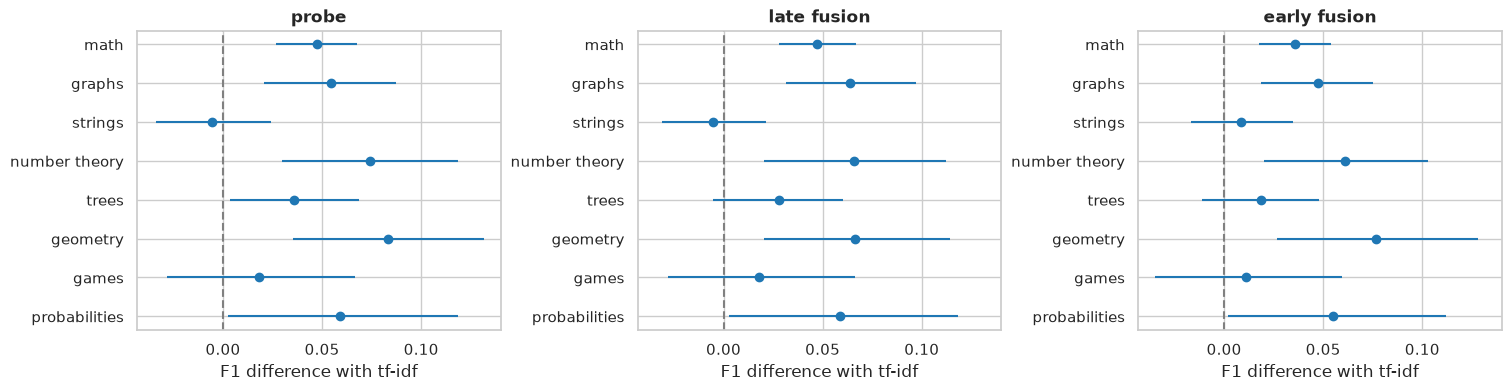

In [13]:
per_tag = pd.concat(
    {
        label: oof.loc[label].loc[list(FOCUS_TAGS), ["delta", "delta_low", "delta_high"]]
        for label in F2LLM
    },
    axis=1,
)
display(per_tag.round(3))
figure, axes = plt.subplots(1, len(F2LLM), sharex=True, figsize=(15, 3.8), layout="constrained")
for ax, label in zip(axes, F2LLM, strict=True):
    plot_intervals(per_tag[label], "delta", "delta_low", "delta_high", ax=ax)
    ax.axvline(0, color="grey", linestyle="--")
    ax.set(title=label, xlabel="F1 difference with tf-idf")
plt.show()

**By release era.** Statements from 2018 on write their math in `$$$` LaTeX, older ones in
flattened Unicode. Both models see release-time cues: the encoder reads the `$$$` marker, and
the TF-IDF normaliser writes `1e5`-style tokens for LaTeX-era statements only. So a difference
per era is read as heterogeneity of the gain, not as a cleaner estimate of it. The macro F1
difference with TF-IDF in each era:

In [14]:
eras = {
    EARLY_ERA: (years < RELEASE_ERA_FIRST_YEAR).to_numpy(),
    LATE_ERA: (years >= RELEASE_ERA_FIRST_YEAR).to_numpy(),
}
# The three F2LLM methods, each paired with tf-idf on the problems of a slice.
against_tfidf = {label: dev_predictions[label] for label in ("tf-idf", *F2LLM)}
paired_names = {"baseline": "tf-idf", "candidate": "method"}
era_gain = slice_differences(
    labels, against_tfidf, groups, baseline="tf-idf", slices=eras, row="macro_f1"
).rename(columns=paired_names)
era_gain.round(3)

problems  tf-idf  method  delta  delta_low  \
slice      method                                                     
up to 2017 probe             1626   0.662   0.708  0.046      0.023   
           late fusion       1626   0.662   0.711  0.049      0.025   
           early fusion      1626   0.662   0.700  0.038      0.017   
from 2018  probe             2362   0.653   0.701  0.048      0.030   
           late fusion       2362   0.653   0.694  0.041      0.024   
           early fusion      2362   0.653   0.696  0.043      0.026   

                         delta_high  
slice      method                    
up to 2017 probe              0.073  
           late fusion        0.075  
           early fusion       0.062  
from 2018  probe              0.068  
           late fusion        0.060  
           early fusion       0.062

**The `math` tag and the time confound.** The share of `math` problems rose from 2019, along
with the multi-test-case input format, so words and cues that signal the release period look
like `math` signal ([notebook 01](01_dataset_overview.ipynb)). The F1 of `math` alone, and its
paired difference with TF-IDF, before and from 2019:

In [15]:
math_eras = {
    f"up to {MATH_SHIFT_YEAR - 1}": (years < MATH_SHIFT_YEAR).to_numpy(),
    f"from {MATH_SHIFT_YEAR}": (years >= MATH_SHIFT_YEAR).to_numpy(),
}
math_gain = slice_differences(
    labels, against_tfidf, groups, baseline="tf-idf", slices=math_eras, row="math"
).rename(columns=paired_names)
math_shares = [labels["math"][math_eras[era]].mean() for era, _ in math_gain.index]
math_gain.insert(1, "math share", math_shares)
math_gain.round(3)

problems  math share  tf-idf  method  delta  \
slice      method                                                      
up to 2018 probe             2004       0.201   0.485   0.527  0.043   
           late fusion       2004       0.201   0.485   0.536  0.051   
           early fusion      2004       0.201   0.485   0.516  0.032   
from 2019  probe             1984       0.365   0.635   0.690  0.055   
           late fusion       1984       0.365   0.635   0.684  0.048   
           early fusion      1984       0.365   0.635   0.674  0.038   

                         delta_low  delta_high  
slice      method                               
up to 2018 probe             0.007       0.080  
           late fusion       0.016       0.088  
           early fusion     -0.002       0.065  
from 2019  probe             0.030       0.078  
           late fusion       0.024       0.071  
           early fusion      0.017       0.060

In [16]:
lines = ["**What it shows**"]
for label in F2LLM:
    table = oof.loc[label].loc[list(FOCUS_TAGS)]
    ahead = ", ".join(f"`{tag}`" for tag in table.index[table["delta_low"] > 0]) or "no tag"
    behind = ", ".join(f"`{tag}`" for tag in table.index[table["delta_high"] < 0]) or "no tag"
    early, late = (era_gain.loc[(era, label), "delta"] for era in eras)
    lines.append(
        f"- **{label}**: ahead of tf-idf on {ahead} and behind on {behind} (intervals that "
        f"exclude 0); the other tags are level within the noise. Macro F1 difference "
        f"{early:+.3f} {EARLY_ERA}, {late:+.3f} {LATE_ERA}."
    )
display(Markdown("\n".join(lines)))

**What it shows**
- **probe**: ahead of tf-idf on `math`, `graphs`, `number theory`, `trees`, `geometry`, `probabilities` and behind on no tag (intervals that exclude 0); the other tags are level within the noise. Macro F1 difference +0.046 up to 2017, +0.048 from 2018.
- **late fusion**: ahead of tf-idf on `math`, `graphs`, `number theory`, `geometry`, `probabilities` and behind on no tag (intervals that exclude 0); the other tags are level within the noise. Macro F1 difference +0.049 up to 2017, +0.041 from 2018.
- **early fusion**: ahead of tf-idf on `math`, `graphs`, `number theory`, `geometry`, `probabilities` and behind on no tag (intervals that exclude 0); the other tags are level within the noise. Macro F1 difference +0.038 up to 2017, +0.043 from 2018.

## 5. Near-duplicate sensitivity

The split keeps the near-duplicate groups of the lexical detector whole, but an embedding can
link two problems that detector missed, and a problem in the training folds that is nearly the
test problem inflates its score. `embedding_pairs.csv` lists the pairs of statement embeddings
to check: `known` is every pair of a frozen group (all of size 2), a gauge of what a duplicate
looks like in embedding space; `flagged` is every pair from different groups, in different dev
folds or in different parts, whose cosine reaches the `PAIRS_QUANTILE` quantile (0.9999) of
all such cosines.

In [17]:
pairs = pd.read_csv(SHARED_ASSETS_DIR / "embedding_pairs.csv")
counts = pd.read_csv(SHARED_ASSETS_DIR / "embedding_pairs_counts.csv").iloc[0]
known = pairs[pairs["kind"] == "known"]
flagged = pairs[pairs["kind"] == "flagged"]
cross_fold = flagged[flagged["relation"] == "cross_fold"]
dev_test = flagged[flagged["relation"] == "dev_test"]
assert len(known) == counts["known_pairs"] and len(flagged) == counts["flagged_pairs"]
print(
    f"{len(known)} known pairs: cosine from {counts['known_min_cosine']:.4f}, median "
    f"{counts['known_median_cosine']:.4f}.\n"
    f"{counts['candidate_pairs']:,.0f} pairs cross a fold or the split: "
    f"{counts['reach_known_min']:,.0f} reach the lowest known cosine, "
    f"{counts['reach_known_median']:,.0f} the median, and {counts['flagged_pairs']:,.0f} are "
    f"flagged (cosine from {counts['cut_cosine']:.4f}): {len(cross_fold)} across dev folds, "
    f"{len(dev_test)} between dev and test."
)

82 known pairs: cosine from 0.7306, median 0.9918.
10,325,659 pairs cross a fold or the split: 156,728 reach the lowest known cosine, 0 the median, and 1,033 are flagged (cosine from 0.8614): 636 across dev folds, 397 between dev and test.


**Out of fold, without the flagged pairs.** A flagged pair across two dev folds can lend a
problem its twin's tags through the training folds. The scores below leave out every dev
problem that is an end of a flagged `cross_fold` pair. The `dev_test` pairs do not touch these
scores, since no fold model trains on the test set; they touch the test references, which come
from a refit on all of dev, and section 10 leaves out their test ends.

In [18]:
involved = pd.concat([cross_fold["sample_id_a"], cross_fold["sample_id_b"]]).unique()
kept = ~labels.index.isin(involved)
print(f"{(~kept).sum()} dev problems end a flagged cross-fold pair; {kept.sum():,} remain")
oof_kept = method_scores(
    labels[kept],
    {label: frame[kept] for label, frame in dev_predictions.items()},
    groups[kept],
    baseline="tf-idf",
)
macro_kept = oof_kept.xs("macro_f1", level="metric")
pd.concat({"all dev problems": macro, "flagged pairs left out": macro_kept}, axis=1).round(3)

699 dev problems end a flagged cross-fold pair; 3,289 remain


all dev problems                                             \
                           f1 f1_low f1_high  delta delta_low delta_high   
method                                                                     
label prior             0.149  0.144   0.153 -0.514    -0.534     -0.494   
tf-idf                  0.663  0.642   0.683  0.000     0.000      0.000   
probe                   0.709  0.689   0.726  0.046     0.031      0.060   
late fusion             0.706  0.687   0.723  0.043     0.028      0.057   
early fusion            0.702  0.682   0.719  0.039     0.026      0.053   

             flagged pairs left out                                             
                                 f1 f1_low f1_high  delta delta_low delta_high  
method                                                                          
label prior                   0.149  0.144   0.154 -0.509    -0.531     -0.486  
tf-idf                        0.658  0.634   0.680  0.000     0.000      0.000  
probe                         0.704  0.680   0.723  0.046     0.029      0.063  
late fusion                   0.700  0.678   0.720  0.042     0.026      0.060  
early fusion                  0.701  0.679   0.721  0.043     0.028      0.059

In [19]:
lines = ["**What it shows**"]
for label in F2LLM:
    row, kept_row = macro.loc[label], macro_kept.loc[label]
    lines.append(
        f"- **{label}**: macro F1 {row['f1']:.3f} on all dev problems, {kept_row['f1']:.3f} with "
        f"the flagged pairs left out; difference with tf-idf {row['delta']:+.3f} and "
        f"{kept_row['delta']:+.3f} [{kept_row['delta_low']:+.3f}, {kept_row['delta_high']:+.3f}]."
    )
display(Markdown("\n".join(lines)))

**What it shows**
- **probe**: macro F1 0.709 on all dev problems, 0.704 with the flagged pairs left out; difference with tf-idf +0.046 and +0.046 [+0.029, +0.063].
- **late fusion**: macro F1 0.706 on all dev problems, 0.700 with the flagged pairs left out; difference with tf-idf +0.043 and +0.042 [+0.026, +0.060].
- **early fusion**: macro F1 0.702 on all dev problems, 0.701 with the flagged pairs left out; difference with tf-idf +0.039 and +0.043 [+0.028, +0.059].

## 6. Thresholds: cross-fitted against pooled, and across the five folds

A threshold chosen on all the out-of-fold scores, then applied to those same scores ("pooled"),
is fitted to the problems it is scored on. The frozen dev predictions use cross-fitted
thresholds instead. The cell below recomputes them from `scores.csv` and fails unless they equal
the frozen `predictions.csv`, then measures the optimism of pooled thresholds: the paired
difference of the macro F1.

In [20]:
fold_thresholds, cross_fitted, pooled = {}, {}, {}
for label, scores in dev_scores.items():
    fold_thresholds[label], cross_fitted[label] = cross_fitted_predictions(scores, labels, folds)
    pooled[label] = apply_thresholds(scores, per_tag_thresholds(scores, labels))
    assert cross_fitted[label].equals(dev_predictions[label]), label
optimism = pd.concat(
    {
        label: compare(labels, cross_fitted[label], pooled[label], groups).loc["macro_f1"]
        for label in dev_scores
    },
    axis=1,
).T.rename(columns={"baseline": "cross-fitted", "candidate": "pooled"})
optimism.round(4)

,cross-fitted,pooled,delta,delta_low,delta_high
tf-idf,0.6629,0.6691,0.0062,0.0022,0.0109
probe,0.7087,0.7191,0.0104,0.0062,0.0150
late fusion,0.7057,0.7193,0.0136,0.0084,0.0190
early fusion,0.7022,0.7127,0.0105,0.0059,0.0152


**Across the five folds.** Fold k's threshold is chosen without fold k's labels, so the five
thresholds of a tag differ with the problems they were chosen on. Each threshold below is
standardised: its distance from the tag's mean out-of-fold score, in standard deviations of
those scores, so the methods share one scale. The table gives the range of the five.

,tf-idf,probe,late fusion,early fusion
math,0.01,0.06,0.19,0.13
graphs,0.09,0.08,0.01,0.10
strings,0.05,0.26,0.25,0.03
number theory,0.19,0.77,0.84,0.45
trees,0.08,0.10,0.05,0.14
geometry,0.03,0.05,0.81,0.09
games,0.01,0.03,0.09,0.39
probabilities,0.22,0.43,0.36,0.24


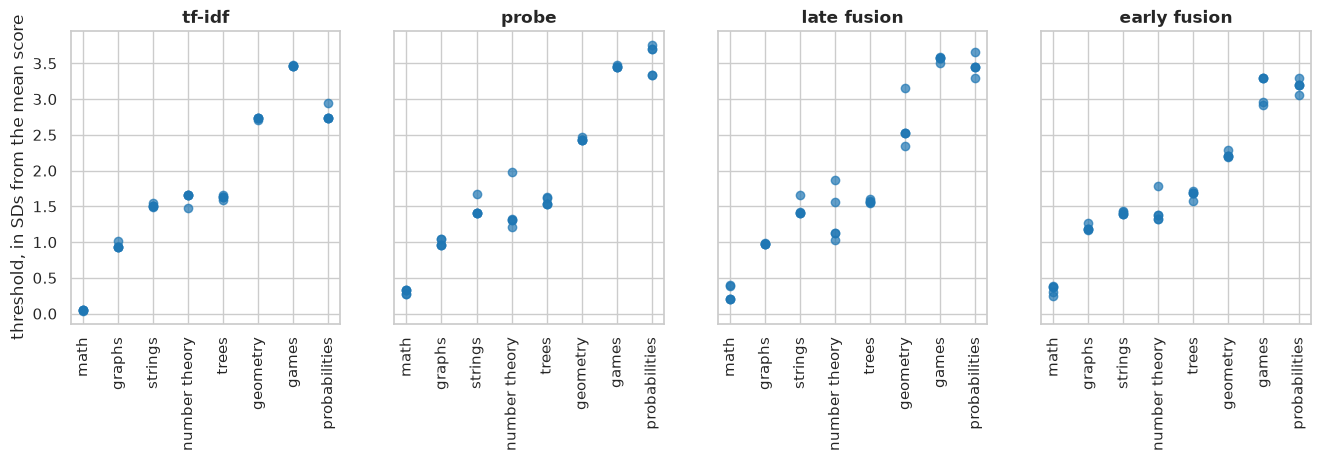

In [21]:
standardised = {
    label: (table - dev_scores[label].mean()) / dev_scores[label].std()
    for label, table in fold_thresholds.items()
}
ranges = pd.DataFrame({label: table.max() - table.min() for label, table in standardised.items()})
display(ranges.round(2))
figure, axes = plt.subplots(1, len(standardised), sharey=True, figsize=(16, 3.8))
for ax, (label, table) in zip(axes, standardised.items(), strict=True):
    ax.plot(
        np.tile(np.arange(len(FOCUS_TAGS)), (len(table), 1)),
        table.to_numpy(),
        "o",
        color=FOCUS_COLOR,
        alpha=0.7,
    )
    ax.set_xticks(range(len(FOCUS_TAGS)), labels=FOCUS_TAGS, rotation=90)
    ax.set_title(label)
axes[0].set_ylabel("threshold, in SDs from the mean score")
plt.show()

In [22]:
lines = ["**What it shows**"]
lines += [
    f"- **{label}**: pooled thresholds score {row['pooled']:.3f} against {row['cross-fitted']:.3f} "
    f"cross-fitted, a paired difference of {row['delta']:+.4f} [{row['delta_low']:+.4f}, "
    f"{row['delta_high']:+.4f}]; the widest range of a tag's five thresholds is "
    f"{ranges[label].max():.2f} SDs (`{ranges[label].idxmax()}`)."
    for label, row in optimism.iterrows()
]
display(Markdown("\n".join(lines)))

**What it shows**
- **tf-idf**: pooled thresholds score 0.669 against 0.663 cross-fitted, a paired difference of +0.0062 [+0.0022, +0.0109]; the widest range of a tag's five thresholds is 0.22 SDs (`probabilities`).
- **probe**: pooled thresholds score 0.719 against 0.709 cross-fitted, a paired difference of +0.0104 [+0.0062, +0.0150]; the widest range of a tag's five thresholds is 0.77 SDs (`number theory`).
- **late fusion**: pooled thresholds score 0.719 against 0.706 cross-fitted, a paired difference of +0.0136 [+0.0084, +0.0190]; the widest range of a tag's five thresholds is 0.84 SDs (`number theory`).
- **early fusion**: pooled thresholds score 0.713 against 0.702 cross-fitted, a paired difference of +0.0105 [+0.0059, +0.0152]; the widest range of a tag's five thresholds is 0.45 SDs (`number theory`).

## 7. Tuning: the grids and their plateau

The three tuned methods searched a grid, each cell scored by its cross-fitted out-of-fold
macro F1 (`tuning/trials.csv` lists every complete trial, one per cell). The grid is small, so
each one is explored whole, and the configuration frozen is the highest value, a tie going to
the lowest cell of the grid, the simplest. A paired comparison of two configurations near the
top has an interval about 0.01 wide (notebook 04, section 4), so the cells within `PLATEAU` of
the best cannot be ranked by the dev set: they form a plateau.

In [23]:
PLATEAU = 0.005
trials = {
    label: pd.read_csv(folders[label] / "tuning" / "trials.csv", float_precision="round_trip")
    for label in F2LLM
}
chosen = {
    label: json.loads((folders[label] / "tuning" / "params.json").read_text(encoding="utf-8"))
    for label in trials
}
display(pd.Series({label: str(params) for label, params in chosen.items()}, name="chosen"))
for label, table in trials.items():
    best = table["value"].max()
    print(
        f"{label}: {len(table)} configurations, best {best:.4f}; "
        f"{(table['value'] >= best - PLATEAU).sum()} within {PLATEAU} of it"
    )
    hidden = ("number", "duration_s")
    grid_columns = [c for c in table.columns if c not in hidden and not c.startswith("f1/")]
    display(table.nlargest(5, "value")[grid_columns].round(4))

probe           {'c': 0.215, 'class_weight': 'none', 'head': 'ridge', 'solution_weight': 1.0}
late fusion                                                                   {'weight': 0.1}
early fusion                     {'c': 0.4, 'solution_weight': 0.25, 'statement_weight': 1.0}
Name: chosen, dtype: str

probe: 168 configurations, best 0.7087; 6 within 0.005 of it


,index,value,head,c,class_weight,solution_weight,micro_f1
131,131,0.7087,ridge,0.2150,none,1.0,0.6638
123,123,0.7081,ridge,0.0464,none,1.0,0.6630
66,66,0.7076,linear_svm,0.0464,none,0.5,0.6653
130,130,0.7068,ridge,0.2150,none,0.5,0.6655
26,26,0.7053,logistic_regression,1.0000,none,0.5,0.6672


late fusion: 19 configurations, best 0.7057; 5 within 0.005 of it


,index,value,weight,micro_f1
1,1,0.7057,0.10,0.6625
0,0,0.7055,0.05,0.6614
2,2,0.7049,0.15,0.6598
6,6,0.7023,0.35,0.6647
7,7,0.7008,0.40,0.6642


early fusion: 80 configurations, best 0.7022; 14 within 0.005 of it


,index,value,c,statement_weight,solution_weight,micro_f1
30,30,0.7022,0.40,1.0,0.25,0.6569
26,26,0.7015,0.40,0.5,0.25,0.6559
10,10,0.7014,0.20,0.5,0.25,0.6596
14,14,0.7010,0.20,1.0,0.25,0.6589
41,41,0.7004,0.62,0.5,0.10,0.6502


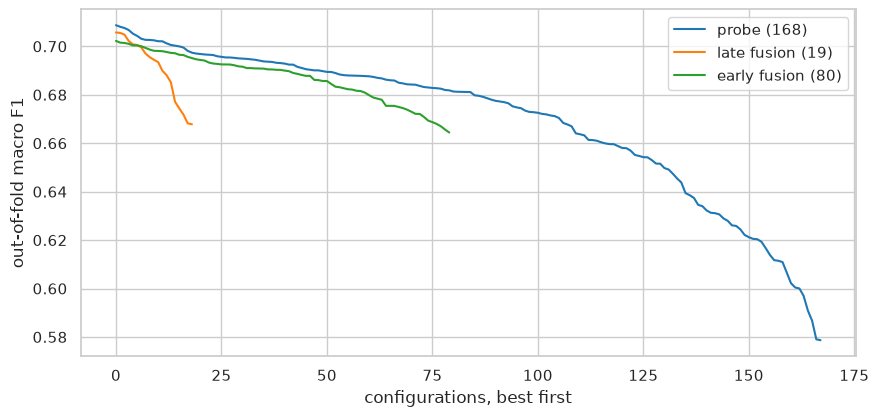

In [24]:
ax = plt.subplots()[1]
for label, table in trials.items():
    ax.plot(np.sort(table["value"].to_numpy())[::-1], label=f"{label} ({len(table)})")
ax.set(xlabel="configurations, best first", ylabel="out-of-fold macro F1")
ax.legend()
plt.show()

## 8. Late fusion's effective weights

Late fusion standardises each model's scores per tag, with the mean and standard deviation of
its inner out-of-fold scores, then blends the two z-scores with one weight `w` on TF-IDF:
`w` in z-space, the same for every tag. In raw-score space, where a blend of the two models'
scores would live, the same fusion multiplies the TF-IDF score by `w / SD_tfidf` and the probe's
by `(1 - w) / SD_probe`. The table gives, per tag, the TF-IDF share of that raw blend, computed
from the two models' held-out (out-of-fold dev) score standard deviations, next to the chosen
`w`, and the correlation of the two models' held-out scores.

In [25]:
weight = chosen["late fusion"]["weight"]
spread = pd.DataFrame({"tf-idf": dev_scores["tf-idf"].std(), "probe": dev_scores["probe"].std()})
raw_tfidf = weight / spread["tf-idf"]
raw_probe = (1 - weight) / spread["probe"]
effective = pd.DataFrame(
    {
        "SD of tf-idf scores": spread["tf-idf"],
        "SD of probe scores": spread["probe"],
        "w": weight,
        "tf-idf share of the raw blend": raw_tfidf / (raw_tfidf + raw_probe),
        "correlation of the scores": dev_scores["tf-idf"].corrwith(dev_scores["probe"]),
    }
)
effective.round(3)

,SD of tf-idf scores,SD of probe scores,w,tf-idf share of the raw blend,correlation of the scores
math,0.448,0.530,0.1,0.116,0.707
graphs,0.394,0.429,0.1,0.108,0.779
strings,0.416,0.392,0.1,0.095,0.866
number theory,0.275,0.335,0.1,0.119,0.722
trees,0.349,0.362,0.1,0.103,0.864
geometry,0.225,0.254,0.1,0.111,0.778
games,0.206,0.195,0.1,0.095,0.827
probabilities,0.146,0.166,0.1,0.112,0.690


In [26]:
share = effective["tf-idf share of the raw blend"]
correlation = effective["correlation of the scores"]
display(
    Markdown(
        "**What it shows**\n"
        f"- The chosen `w` is {weight:.2f} on the tf-idf z-scores, for every tag.\n"
        f"- In raw scores that is a tf-idf share of {share.min():.2f} (`{share.idxmin()}`) to "
        f"{share.max():.2f} (`{share.idxmax()}`), from the two models' score scales.\n"
        f"- The held-out scores of the two models correlate at {correlation.min():.2f} "
        f"(`{correlation.idxmin()}`) to {correlation.max():.2f} (`{correlation.idxmax()}`)."
    )
)

**What it shows**
- The chosen `w` is 0.10 on the tf-idf z-scores, for every tag.
- In raw scores that is a tf-idf share of 0.09 (`strings`) to 0.12 (`number theory`), from the two models' score scales.
- The held-out scores of the two models correlate at 0.69 (`probabilities`) to 0.87 (`strings`).

## 9. Latency and eligibility

`tracking latency` timed each method on 50 dev problems drawn with a fixed seed: the load apart,
one untimed warm-up, then each problem alone, then one call over all 50, in float32 and with no
cache (on the GPU, a loaded method encodes the 50 one at a time even in that call). It timed them twice, on the same problems. A loaded method encodes on the GPU when torch
sees one, else on the CPU, unless `CODEFORCES_DEVICE` names a device, so `latency.csv`,
the file that the CLI and ADR 0004's rule read, holds the timings on the GPU, one problem per
call. The first timings, on the CPU, taken when a loaded method encoded on the CPU by default,
are kept beside them in `analysis/cpu/latency.csv`, as the ModernBERT methods keep theirs: they
are what a user without a GPU gets. A method is eligible for the CLI when its dev scores are
out of fold (not `dev_in_sample`) and the slowest problem of its `latency.csv` takes under 10
seconds, the load apart ([ADR 0004](../docs/adr/0004-tagging-method-framework.md)); an
ineligible one is a reference.

The CPU timings were taken on a machine that was not idle: by choice, the three methods were
timed while another job loaded it. The message of the commit that added the three CPU timing
files records a one-minute load average of 3.8, 7.0 and 11.3 before the timings of the probe,
late fusion and early fusion, where the idle protocol asks for below 1.0. These CPU timings
overstate an idle machine's latency.

median_s  p95_s  max_s  load_s  one call over 50, s  \
device method                                                              
GPU    probe             0.13   0.19   0.24   12.07                 6.98   
       late fusion       0.14   0.20   0.24    8.84                 7.21   
       early fusion      0.14   0.20   0.24    8.42                 6.96   
CPU    probe             3.66   6.60   7.91    7.49               212.89   
       late fusion       3.03   6.89   8.48    7.81               289.28   
       early fusion      3.70   6.13   7.22    8.85               242.53   

                     load and slowest problem, s  slowest under budget  
device method                                                           
GPU    probe                               12.31                  True  
       late fusion                          9.08                  True  
       early fusion                         8.66                  True  
CPU    probe                               15.40                  True  
       late fusion                         16.29                  True  
       early fusion                        16.07                  True

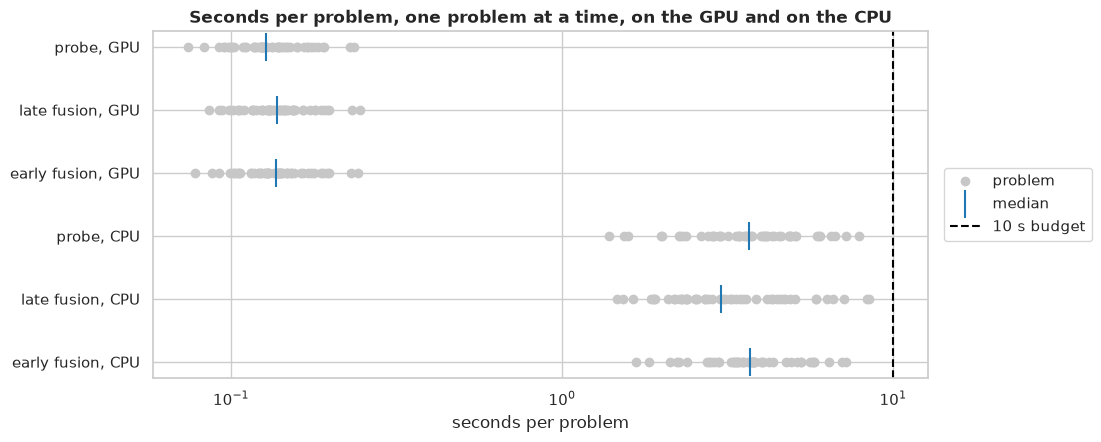

In [27]:
# latency.csv holds the GPU timings; analysis/cpu/latency.csv the CPU timings of the same problems.
CPU_LATENCY_DIR = Path("analysis", "cpu")
timings = {
    "GPU": {label: load_latency(folder) for label, folder in folders.items()},
    "CPU": {label: load_latency(folder / CPU_LATENCY_DIR) for label, folder in folders.items()},
}
assert all(
    list(timed.seconds.index) == list(timings["GPU"][label].seconds.index)
    for device_timings in timings.values()
    for label, timed in device_timings.items()
)
latency_by_device = pd.concat(
    {
        device: pd.DataFrame(
            {
                label: {
                    **latency_summary(timed.seconds),
                    "load_s": timed.load_s,
                    "one call over 50, s": timed.bulk_s,
                }
                for label, timed in device_timings.items()
            }
        ).T
        for device, device_timings in timings.items()
    },
    names=["device", "method"],
)
latency_by_device["load and slowest problem, s"] = (
    latency_by_device["load_s"] + latency_by_device["max_s"]
)
latency_by_device["slowest under budget"] = latency_by_device["max_s"] < LATENCY_BUDGET_S
latency, cpu_latency = latency_by_device.loc["GPU"].copy(), latency_by_device.loc["CPU"]
in_sample = pd.Series({label: records[label].method_entries["dev_in_sample"] for label in F2LLM})
latency["eligible"] = latency["slowest under budget"] & ~in_sample.astype(bool)
display(latency_by_device.round(2))
ax = plot_latency(
    {
        f"{label}, {device}": timed.seconds
        for device, device_timings in timings.items()
        for label, timed in device_timings.items()
    }
)
ax.set(title="Seconds per problem, one problem at a time, on the GPU and on the CPU")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()

In [28]:
eligible = latency.index[latency["eligible"]].tolist()
speedup = cpu_latency["median_s"] / latency["median_s"]
cpu_under = cpu_latency.index[cpu_latency["slowest under budget"]].tolist()
lines = [
    "**What it shows**",
    f"- Eligible (out of fold, slowest problem of `latency.csv` under {LATENCY_BUDGET_S:g} s): "
    f"{', '.join(eligible) or 'none'}; "
    f"references: {', '.join(latency.index.difference(eligible)) or 'none'}.",
    "- **On the GPU**, one problem per call, the median problem takes "
    + ", ".join(f"{label} {seconds:.3f} s" for label, seconds in latency["median_s"].items())
    + ", and the slowest "
    + ", ".join(f"{label} {seconds:.3f} s" for label, seconds in latency["max_s"].items())
    + f", against a budget of {LATENCY_BUDGET_S:g} s.",
    "- **On the CPU** (`analysis/cpu/latency.csv`, timed under load), the median problem takes "
    + ", ".join(f"{label} {seconds:.2f} s" for label, seconds in cpu_latency["median_s"].items())
    + ", and the slowest "
    + ", ".join(f"{label} {seconds:.2f} s" for label, seconds in cpu_latency["max_s"].items())
    + f": {speedup.min():.0f} to {speedup.max():.0f} times the GPU's median; slowest problem "
    f"under the budget on the CPU: {', '.join(cpu_under) or 'none'}.",
]
one_shot = latency["load and slowest problem, s"]
cpu_one_shot = cpu_latency["load and slowest problem, s"]
over = one_shot.index[one_shot >= LATENCY_BUDGET_S].tolist()
if not over:
    budget = (
        f"on the GPU even that stays under the {LATENCY_BUDGET_S:g} s budget, with "
        f"{LATENCY_BUDGET_S - one_shot.max():.2f} s left at the least for the interpreter's "
        "start-up and the cold first call"
    )
elif len(over) == len(one_shot):
    budget = (
        f"on the GPU it exceeds the {LATENCY_BUDGET_S:g} s budget for every method, so a CLI "
        "that meets it on each call loads the method once, then predicts problem after problem"
    )
else:
    budget = (
        f"on the GPU it exceeds the {LATENCY_BUDGET_S:g} s budget for {', '.join(over)}, so a "
        "CLI that meets it on each call with those loads the method once"
    )
lines.append(
    "- Loading, paid once per process, takes "
    + ", ".join(f"{label} {seconds:.2f} s" for label, seconds in latency["load_s"].items())
    + " on the GPU; a one-shot process that loads the method for a single prediction takes at "
    "least the load plus the slowest warm problem (interpreter start-up and the cold first call "
    "come on top): "
    + ", ".join(f"{label} {seconds:.2f} s" for label, seconds in one_shot.items())
    + " on the GPU, "
    + ", ".join(f"{label} {seconds:.2f} s" for label, seconds in cpu_one_shot.items())
    + " on the CPU. Eligibility follows ADR 0004, on the slowest warm problem with the load "
    "apart; " + budget + "."
)
if eligible:
    best = macro.loc[eligible, "f1"].idxmax()
    lines.append(
        f"- Among these three alone, ADR 0004 picks **{best}** (dev out-of-fold macro F1 "
        f"{macro.at[best, 'f1']:.3f}). The CLI's method is chosen across every frozen method, "
        f"the frozen TF-IDF method among them (dev out-of-fold macro F1 "
        f"{macro.at['tf-idf', 'f1']:.3f})."
    )
display(Markdown("\n".join(lines)))

**What it shows**
- Eligible (out of fold, slowest problem of `latency.csv` under 10 s): probe, late fusion, early fusion; references: none.
- **On the GPU**, one problem per call, the median problem takes probe 0.127 s, late fusion 0.138 s, early fusion 0.137 s, and the slowest probe 0.236 s, late fusion 0.245 s, early fusion 0.242 s, against a budget of 10 s.
- **On the CPU** (`analysis/cpu/latency.csv`, timed under load), the median problem takes probe 3.66 s, late fusion 3.03 s, early fusion 3.70 s, and the slowest probe 7.91 s, late fusion 8.48 s, early fusion 7.22 s: 22 to 29 times the GPU's median; slowest problem under the budget on the CPU: probe, late fusion, early fusion.
- Loading, paid once per process, takes probe 12.07 s, late fusion 8.84 s, early fusion 8.42 s on the GPU; a one-shot process that loads the method for a single prediction takes at least the load plus the slowest warm problem (interpreter start-up and the cold first call come on top): probe 12.31 s, late fusion 9.08 s, early fusion 8.66 s on the GPU, probe 15.40 s, late fusion 16.29 s, early fusion 16.07 s on the CPU. Eligibility follows ADR 0004, on the slowest warm problem with the load apart; on the GPU it exceeds the 10 s budget for probe, so a CLI that meets it on each call with those loads the method once.
- Among these three alone, ADR 0004 picks **probe** (dev out-of-fold macro F1 0.709). The CLI's method is chosen across every frozen method, the frozen TF-IDF method among them (dev out-of-fold macro F1 0.663).

## 10. The test references

Each method scored the test set once, when it was frozen. These scores are references: they
are reported next to the dev scores and never used to choose a method or a configuration
([ADR 0001](../docs/adr/0001-model-selection-protocol.md)). The test intervals are wider than
the dev ones, since the test set is a quarter of the dev set's size.

In [29]:
test_results = {
    label: evaluate(test_labels, frame, groups=test_groups)
    for label, frame in test_predictions.items()
}
test_summary = pd.DataFrame(
    {label: result.summary.loc[ALL_PROBLEMS] for label, result in test_results.items()}
).T
pd.DataFrame(
    {
        "dev out-of-fold macro F1": macro["f1"],
        "test macro F1": test_summary["macro_f1"],
        "test, low": test_summary["macro_f1_low"],
        "test, high": test_summary["macro_f1_high"],
        "test micro F1": test_summary["micro_f1"],
    }
).round(3)

,dev out-of-fold macro F1,test macro F1,"test, low","test, high",test micro F1
label prior,0.149,0.149,0.139,0.158,0.158
tf-idf,0.663,0.689,0.649,0.721,0.633
probe,0.709,0.741,0.708,0.770,0.695
late fusion,0.706,0.748,0.715,0.775,0.699
early fusion,0.702,0.730,0.696,0.759,0.687


**The score scale between dev and test.** A dev score comes from a model fitted on four folds,
a test score from the refit on all of dev, and the thresholds were chosen on the former. If
the refit's scores sit on another scale, the thresholds transfer only approximately. Below, the
shift of each tag's mean score from dev to test, in standard deviations of the dev scores, and
the number of tags predicted per problem:

In [30]:
shift = pd.DataFrame(
    {
        label: (test_scores[label].mean() - dev_scores[label].mean()) / dev_scores[label].std()
        for label in dev_scores
    }
)
display(shift.round(2))
pd.DataFrame(
    {
        "tags per problem, dev out of fold": {
            label: frame.sum(axis=1).mean() for label, frame in dev_predictions.items()
        },
        "tags per problem, test": {
            label: frame.sum(axis=1).mean() for label, frame in test_predictions.items()
        },
    }
).round(3)

,tf-idf,probe,late fusion,early fusion
math,-0.04,-0.01,-0.01,-0.01
graphs,-0.05,-0.03,-0.03,-0.05
strings,-0.00,0.04,0.04,0.00
number theory,0.01,0.03,0.03,0.02
trees,-0.07,0.02,0.01,-0.03
geometry,-0.00,-0.02,-0.02,-0.04
games,-0.07,0.01,0.00,-0.08
probabilities,0.01,0.03,0.03,-0.03


,"tags per problem, dev out of fold","tags per problem, test"
label prior,8.000,8.000
tf-idf,0.826,0.843
probe,0.764,0.795
late fusion,0.776,0.807
early fusion,0.754,0.779


In [31]:
lines = ["**What it shows**"]
for label in F2LLM:
    row = test_summary.loc[label]
    lines.append(
        f"- **{label}**: test macro F1 {row['macro_f1']:.3f} [{row['macro_f1_low']:.3f}, "
        f"{row['macro_f1_high']:.3f}] against {macro.at[label, 'f1']:.3f} out of fold; mean "
        f"score shift {shift[label].abs().mean():.2f} SDs."
    )
lines.append(
    f"- **tf-idf**, the frozen method `{TFIDF}`: test macro F1 "
    f"{test_summary.at['tf-idf', 'macro_f1']:.3f}, out of fold {macro.at['tf-idf', 'f1']:.3f}."
)
# The test ends of section 5's flagged dev-test pairs: the frozen test predictions without them.
twin = test_labels.index.isin(pd.concat([dev_test["sample_id_a"], dev_test["sample_id_b"]]))
without_twins = {
    label: evaluate(test_labels[~twin], frame[~twin]).macro_f1
    for label, frame in test_predictions.items()
}
lines.append(
    f"- **Dev-test twins**: {twin.sum()} test problems ({twin.mean():.1%} of the test set) end "
    "a flagged `dev_test` pair of section 5: their twin is in dev, which the refit trained on. "
    "Test macro F1 without them (the frozen test predictions, restricted), and its change: "
    + ", ".join(
        f"{label} {score:.3f} ({score - test_results[label].macro_f1:+.4f})"
        for label, score in without_twins.items()
    )
    + "."
)
display(Markdown("\n".join(lines)))

**What it shows**
- **probe**: test macro F1 0.741 [0.708, 0.770] against 0.709 out of fold; mean score shift 0.02 SDs.
- **late fusion**: test macro F1 0.748 [0.715, 0.775] against 0.706 out of fold; mean score shift 0.02 SDs.
- **early fusion**: test macro F1 0.730 [0.696, 0.759] against 0.702 out of fold; mean score shift 0.03 SDs.
- **tf-idf**, the frozen method `tfidf`: test macro F1 0.689, out of fold 0.663.
- **Dev-test twins**: 199 test problems (20.0% of the test set) end a flagged `dev_test` pair of section 5: their twin is in dev, which the refit trained on. Test macro F1 without them (the frozen test predictions, restricted), and its change: label prior 0.149 (-0.0001), tf-idf 0.681 (-0.0074), probe 0.740 (-0.0017), late fusion 0.746 (-0.0016), early fusion 0.729 (-0.0009).

## 11. Caveats and takeaways

**Caveats**
- **Selection bias.** Each tuned method's configuration is the best of its grid on the
  out-of-fold labels, late fusion inherits the probe's choice, and TF-IDF is the best of its
  study's 203 trials (notebook 04). The best of many noisy scores sits above its true value: a
  difference inside its interval is no evidence.
- **Contamination.** Qwen3's pretraining data is not disclosed and may include Codeforces pages
  with their tags. That can only help the embedding methods against TF-IDF, so a gain over
  TF-IDF is an upper bound. The self-identifying slice measures part of it (section 3). F2LLM
  v2 was left out because its training data holds xCodeEval itself.
- **Near-duplicates the lexical groups missed** can favour the embeddings over TF-IDF. Section 5
  bounds them for the out-of-fold scores, leaving out the dev problems of a flagged cross-fold
  pair; section 10 bounds them for the test references, which come from a refit on all of dev,
  leaving out the test problems of a flagged dev-test pair.
- **Release era.** Both models read release-time cues (section 4), so a per-era difference
  measures the gain within each period, not a gain free of the cues.
- **GPU to CPU.** The cached embeddings come from the GPU (`embed --device cuda`), in batches;
  a loaded method's from the GPU when torch sees one, else from the CPU, one problem at a time
  (`CODEFORCES_DEVICE` overrides it). `score_atol` was measured on the CPU, the device
  furthest from the batched GPU path, to cover the gap. `freeze` checked a loaded method's
  scores within it on 3 dev problems (`_FOLDER_CHECK_PROBLEMS`), live on the CPU; `verify`, run
  with `--device cuda`, re-predicted every test problem live, on the GPU, one problem per call.
- **Score scale.** The refit's scores can sit on another scale than the fold models'
  (section 10): the shift is measured, not corrected.
- **Latency** depends on the device and the machine's load. Section 9's headline timings,
  `latency.csv`, are the GPU's; the CPU timings beside them were taken while another job
  loaded the machine, by choice, so they overstate an idle machine's CPU latency. Section 9
  gives each method's slowest problem against the budget on both devices, and the load a
  one-shot call adds.

**Takeaways**

In [32]:
best_macro = macro.loc[F2LLM, "f1"].idxmax()
best_f1 = (
    f"{macro.at[best_macro, 'f1']:.3f} [{macro.at[best_macro, 'f1_low']:.3f}, "
    f"{macro.at[best_macro, 'f1_high']:.3f}]"
)
pick = macro.loc[eligible, "f1"].idxmax() if eligible else None
if tied.all() and pick is not None:
    among = (
        "the three are not distinguishable on dev, every paired interval between them including "
        "0, and among the eligible ones ADR 0004 picks the highest macro F1 mechanically: "
        f"{pick}, {macro.at[pick, 'f1']:.3f} [{macro.at[pick, 'f1_low']:.3f}, "
        f"{macro.at[pick, 'f1_high']:.3f}]"
    )
elif tied.all():
    among = (
        "the three are not distinguishable on dev, every paired interval between them including "
        "0, and none is eligible for the CLI"
    )
else:
    among = (
        f"{best_macro} has the highest macro F1 of the three, {best_f1}; the paired differences "
        f"between them whose interval excludes 0: {', '.join(between.index[~tied])}"
    )
ahead_of_tfidf = macro.loc[F2LLM].index[macro.loc[F2LLM, "delta_low"] > 0].tolist()
eligible_count = "all three" if len(eligible) == len(F2LLM) else f"{len(eligible)} of the three"
display(
    Markdown(
        f"- **Out of fold** (section 3): {among}, against {macro.at['tf-idf', 'f1']:.3f} for the "
        f"frozen TF-IDF method `{TFIDF}`. Methods whose paired difference with TF-IDF excludes 0 "
        f"on the upside: {', '.join(ahead_of_tfidf) or 'none'}.\n"
        f"- **Eligibility** (section 9): {eligible_count} ({', '.join(eligible) or 'none'}) "
        f"take under {LATENCY_BUDGET_S:g} s for their slowest problem on the GPU, one problem per "
        f"call, the load apart: {latency['median_s'].min():.3f} to "
        f"{latency['median_s'].max():.3f} s at the median, {latency['max_s'].max():.3f} s at "
        f"most ({latency['max_s'].idxmax()}). On the CPU, timed under load, the median problem "
        f"takes {cpu_latency['median_s'].min():.2f} to {cpu_latency['median_s'].max():.2f} s and "
        f"the slowest {cpu_latency['max_s'].max():.2f} s ({cpu_latency['max_s'].idxmax()}). A "
        f"one-shot call, the load included, takes at least {one_shot.min():.2f} to "
        f"{one_shot.max():.2f} s on the GPU, {cpu_one_shot.min():.2f} to "
        f"{cpu_one_shot.max():.2f} s on the CPU.\n"
        "- **Next steps**: time the CPU path again on an idle machine, since its timings "
        "overstate an idle machine's latency; choose the CLI's method across every frozen "
        "method, not these three alone, on dev out-of-fold macro F1 "
        "([ADR 0004](../docs/adr/0004-tagging-method-framework.md)); freeze the fourth method of "
        "section 1 only if wanted, at 5 to 7 hours of GPU."
    )
)

- **Out of fold** (section 3): the three are not distinguishable on dev, every paired interval between them including 0, and among the eligible ones ADR 0004 picks the highest macro F1 mechanically: probe, 0.709 [0.689, 0.726], against 0.663 for the frozen TF-IDF method `tfidf`. Methods whose paired difference with TF-IDF excludes 0 on the upside: probe, late fusion, early fusion.
- **Eligibility** (section 9): all three (probe, late fusion, early fusion) take under 10 s for their slowest problem on the GPU, one problem per call, the load apart: 0.127 to 0.138 s at the median, 0.245 s at most (late fusion). On the CPU, timed under load, the median problem takes 3.03 to 3.70 s and the slowest 8.48 s (late fusion). A one-shot call, the load included, takes at least 8.66 to 12.31 s on the GPU, 15.40 to 16.29 s on the CPU.
- **Next steps**: time the CPU path again on an idle machine, since its timings overstate an idle machine's latency; choose the CLI's method across every frozen method, not these three alone, on dev out-of-fold macro F1 ([ADR 0004](../docs/adr/0004-tagging-method-framework.md)); freeze the fourth method of section 1 only if wanted, at 5 to 7 hours of GPU.